<a href="https://colab.research.google.com/github/sanchit-Thakur/ML-COURSE/blob/main/Machine_Learning_course.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import RandomOverSampler

In [ ]:
df = pd.read_csv("/content/Social_media_impact_on_life.csv")
print(df.head(8))
print(df.info)

    Student_ID  Age  ... Academic_Performance_GPA Overall_Impact
0  STU_2024000   19  ...                     2.73        Neutral
1  STU_2024001   19  ...                     3.21     Beneficial
2  STU_2024002   17  ...                     3.00        Neutral
3  STU_2024003   16  ...                     3.42     Beneficial
4  STU_2024004   17  ...                     3.41     Beneficial
5  STU_2024005   16  ...                     3.21     Beneficial
6  STU_2024006   20  ...                     3.72     Beneficial
7  STU_2024007   19  ...                     3.37     Beneficial

[8 rows x 16 columns]
<bound method DataFrame.info of        Student_ID  Age  ... Academic_Performance_GPA Overall_Impact
0     STU_2024000   19  ...                     2.73        Neutral
1     STU_2024001   19  ...                     3.21     Beneficial
2     STU_2024002   17  ...                     3.00        Neutral
3     STU_2024003   16  ...                     3.42     Beneficial
4     STU_2024004   

In [ ]:
cols = ("flength" , "fwidth" , "fconc" , "fconc1" , "fasym" , "fm3long", "falpha")
df = pd.read_csv("/content/Social_media_impact_on_life.csv", names = cols)
df.head()

,,,,,,,,,flength,fwidth,fconc,fconc1,fasym,fm3long,falpha
Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.0,Neutral
STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial


In [ ]:
df = pd.read_csv("/content/Social_media_impact_on_life.csv")

print("Unique classes in 'Overall_Impact':", df["Overall_Impact"].unique())

Unique classes in 'Overall_Impact': ['Neutral' 'Beneficial' 'Negative']


In [ ]:
df = pd.read_csv("/content/Social_media_impact_on_life.csv")

impact_map = {"Beneficial": 1, "Neutral": 2, "Negative": 0}
df["Overall_Impact"] = df["Overall_Impact"].map(impact_map).astype(int)

print(df["Overall_Impact"].value_counts())

Overall_Impact
1    3681
2     654
0     165
Name: count, dtype: int64


In [ ]:
df.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,2
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,1
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,2
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,1
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,1


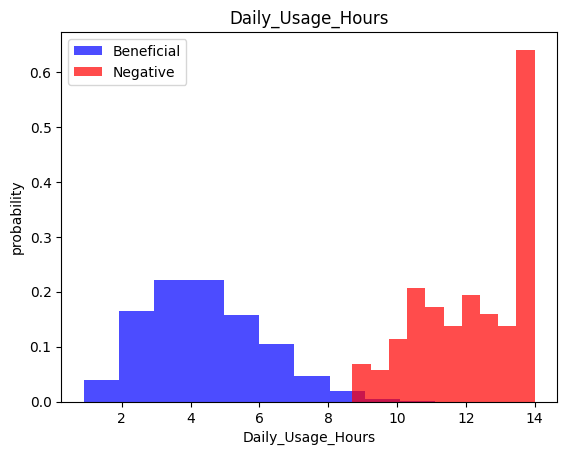

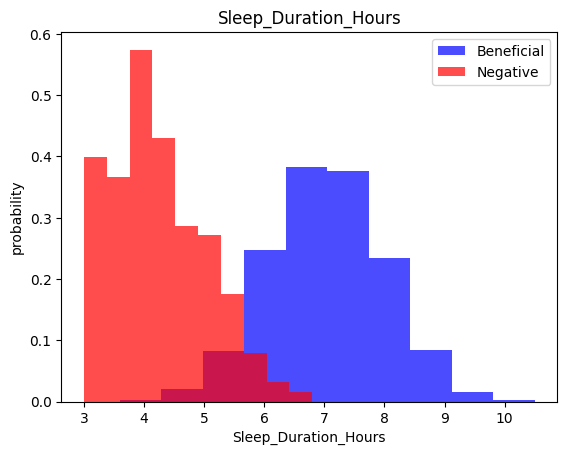

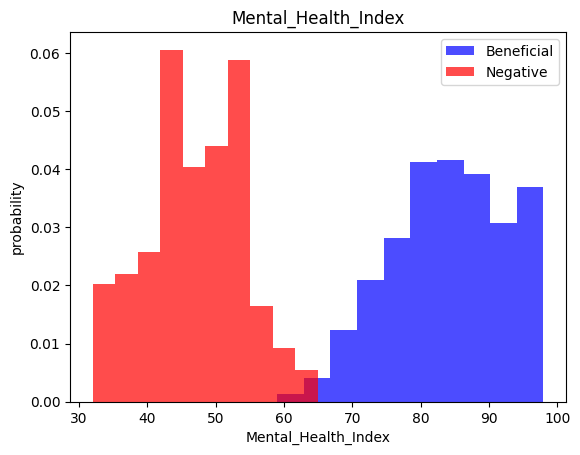

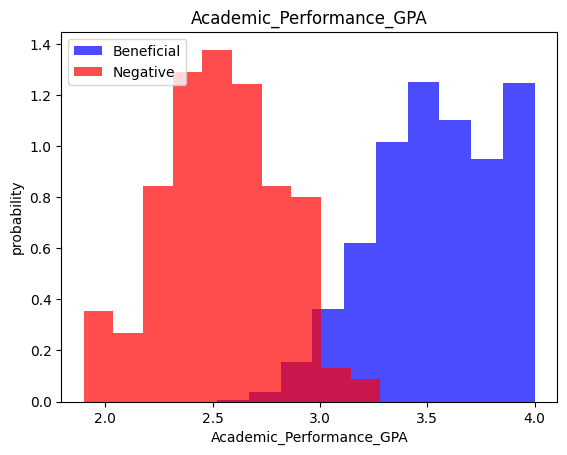

In [ ]:
plot_cols = ["Daily_Usage_Hours", "Sleep_Duration_Hours", "Mental_Health_Index", "Academic_Performance_GPA"]

for label in plot_cols:
  plt.hist(df[df["Overall_Impact"] == 1][label], color='blue', label='Beneficial', alpha=0.7, density=True)
  plt.hist(df[df["Overall_Impact"] == 0][label], color='red', label='Negative', alpha=0.7, density=True)
  plt.title(label)
  plt.ylabel("probability")
  plt.xlabel(label)
  plt.legend()
  plt.show()

Train , Validation ans Test datasets


In [ ]:
train , valid , test = np.split(df.sample(frac=1), [int(0.6*len(df)), int(0.8*len(df))])
def scale_dataset(dataframe , oversampler = False):
  x = dataframe[dataframe.columns[:-1]].values
  y = dataframe[dataframe.columns[-1]].values

  scaler = StandardScaler()
  x = scaler.fit_transform(x)
  if oversampler:
    ros = RandomOverSampler()
    x , y = ros.fit_resample(x,y)

  df = np.hstack((x,np.reshape(y ,(-1, 1))))
  return data, x,y

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [ ]:
def scale_dataset_fixed(dataframe, numerical_cols, target_col, oversampler=False):
    x = dataframe[numerical_cols].values
    y = dataframe[target_col].values

    from sklearn.impute import SimpleImputer
    imputer = SimpleImputer(strategy='median')
    x = imputer.fit_transform(x)

    scaler = StandardScaler()
    x = scaler.fit_transform(x)

    if oversampler:
        ros = RandomOverSampler()
        x, y = ros.fit_resample(x, y)

    scaled_df = np.hstack((x, np.reshape(y, (-1, 1))))
    return scaled_df, x, y

num_cols = ["Daily_Usage_Hours", "Sleep_Duration_Hours", "Mental_Health_Index", "Academic_Performance_GPA"]
target = "Overall_Impact"



In [ ]:
len(Y_train)

6612

In [ ]:
sum(Y_train == 1)

np.int64(2204)

In [ ]:
sum(Y_train == 0)

np.int64(2204)

In [ ]:
len(x_train)

6612

KNN(K-NEAREST NEIGHBORS)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

In [ ]:
knn_model = KNeighborsClassifier(n_neighbors=1)
knn_model.fit(x_train, Y_train)

KNeighborsClassifier(n_neighbors=1)

In [ ]:
train_scaled, x_train, Y_train = scale_dataset_fixed(train, num_cols, target, oversampler=True)
valid_scaled, x_valid, Y_valid = scale_dataset_fixed(valid, num_cols, target, oversampler=False)
test_scaled, x_test, Y_test = scale_dataset_fixed(test, num_cols, target, oversampler=False)

# Retrain KNN model on the correct training data
knn_model = KNeighborsClassifier(n_neighbors=1)
knn_model.fit(x_train, Y_train)

# Predict and evaluate on the test data
y_pred_test = knn_model.predict(x_test)
print("KNN Test Classification Report:")
print(classification_report(Y_test, y_pred_test))

KNN Test Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.74      0.68        31
           1       0.96      0.96      0.96       745
           2       0.69      0.63      0.66       124

    accuracy                           0.91       900
   macro avg       0.76      0.78      0.77       900
weighted avg       0.91      0.91      0.91       900



In [ ]:
y_pred = knn_model.predict(x_train)
x_pred = knn_model.predict(x_test)

In [ ]:
y_pred

array([2, 1, 1, ..., 2, 2, 2])

In [ ]:
x_pred

array([1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
       1, 1, 1, 1, 1, 2, 0, 1, 2, 2, 1, 1, 1, 2, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 2, 2, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 2, 1, 0, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 2, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 1, 1,
       2, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 0, 2, 1, 1, 1, 1, 1, 2, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 2,

In [ ]:
Y_test

array([1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 2, 1, 1, 2, 1, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 2, 1, 2, 0, 2, 2, 2, 1, 1, 1, 2, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 0, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 2,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 0, 1, 2, 1, 1, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 2, 1, 1, 1, 1, 1,
       2, 1, 1, 1, 2, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 0, 2, 1, 1, 1, 1, 1, 2, 1, 1,
       2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 2, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 2,

In [ ]:
Y_train

array([2, 1, 1, ..., 2, 2, 2])

In [ ]:
x_train

array([[ 1.23956994, -2.00981657, -1.3111035 , -0.71502409],
       [ 0.54809812, -0.59425732, -1.07926761,  0.1012717 ],
       [-1.10375122,  0.0718882 ,  1.00725538,  0.56043807],
       ...,
       [ 1.89262666, -1.01059828, -1.92933253, -1.58233836],
       [ 1.39323034, -0.7607937 , -0.84743172, -1.45479214],
       [ 1.35481524, -0.34445275, -1.3111035 ,  0.30534564]])

In [ ]:
x_test

array([[ 0.09191506, -0.15117136, -0.24975904, -0.83196888],
       [-0.10163561,  0.27293782, -0.0113888 ,  1.47377837],
       [ 1.56290018, -0.74492422, -1.12378324, -1.0910416 ],
       ...,
       [ 0.2467556 ,  0.18811599,  0.70372191,  0.30795111],
       [ 0.16933533, -1.16903341, -0.24975904, -1.68690887],
       [ 1.64032045, -1.84760811, -1.44161022, -2.30868341]])

Naïve Bayes


In [ ]:
from sklearn.naive_bayes import GaussianNB

In [ ]:
nb_model = GaussianNB()
nb_model.fit(x_train , Y_train)

GaussianNB()

In [ ]:
x_pred = nb_model.predict(x_test)
print(classification_report(Y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.62      0.74      0.68        31
           1       0.96      0.96      0.96       745
           2       0.69      0.63      0.66       124

    accuracy                           0.91       900
   macro avg       0.76      0.78      0.77       900
weighted avg       0.91      0.91      0.91       900



logistic regression


In [ ]:
from sklearn.linear_model import LogisticRegression

In [ ]:
lg_model = LogisticRegression()
lg_model.fit(x_train , Y_train)


LogisticRegression()

In [ ]:
x_pred = lg_model.predict(x_test)
print(classification_report(Y_test, y_pred_test))

              precision    recall  f1-score   support

           0       0.62      0.74      0.68        31
           1       0.96      0.96      0.96       745
           2       0.69      0.63      0.66       124

    accuracy                           0.91       900
   macro avg       0.76      0.78      0.77       900
weighted avg       0.91      0.91      0.91       900



SVM


In [ ]:
from sklearn.svm import SVC


In [ ]:
svm_model = SVC()
svm_model.fit(x_train, Y_train)

SVC()

In [ ]:
y_pred = svm_model.predict(x_test)
print(classification_report(Y_test , y_pred))

              precision    recall  f1-score   support

           0       0.61      0.90      0.73        31
           1       0.99      0.91      0.95       745
           2       0.60      0.81      0.69       124

    accuracy                           0.90       900
   macro avg       0.73      0.87      0.79       900
weighted avg       0.92      0.90      0.91       900



Neural net

In [ ]:
import tensorflow as tf


In [ ]:
def plot_loss(history):
  fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

  ax1.plot(history.history['loss'], label='loss')
  ax1.plot(history.history['val_loss'], label='val_loss')
  ax1.set_xlabel('Epoch')
  ax1.set_ylabel('Binary crossentropy')
  ax1.legend()
  ax1.grid(True)

  ax2.plot(history.history['accuracy'], label='accuracy')
  ax2.plot(history.history['val_accuracy'], label='val_accuracy')
  ax2.set_xlabel('Epoch')
  ax2.set_ylabel('Accuracy')
  ax2.legend()
  ax2.grid(True)

  plt.show()

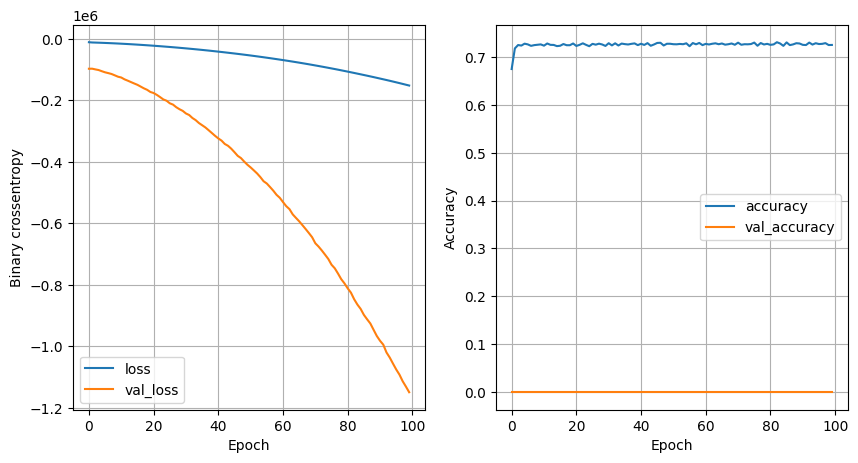

In [ ]:
plot_loss(history)

In [ ]:
def train_model(x_train, Y_train, num_nodes, dropout_prob, lr, batch_size, epochs):
  nn_model = tf.keras.Sequential([
      tf.keras.layers.Dense(num_nodes, activation='relu', input_shape=(4,)),
      tf.keras.layers.Dropout(dropout_prob),
      tf.keras.layers.Dense(32, activation='relu'),
      tf.keras.layers.Dropout(dropout_prob),
      tf.keras.layers.Dense(1, activation='sigmoid')
  ])
  nn_model.compile(optimizer=tf.keras.optimizers.Adam(lr), loss='binary_crossentropy', metrics=['accuracy'])
  history = nn_model.fit(x_train, Y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2, verbose=0)
  return nn_model, history

16 nodes , dropout 0 , lr 0.1, batch size 32


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


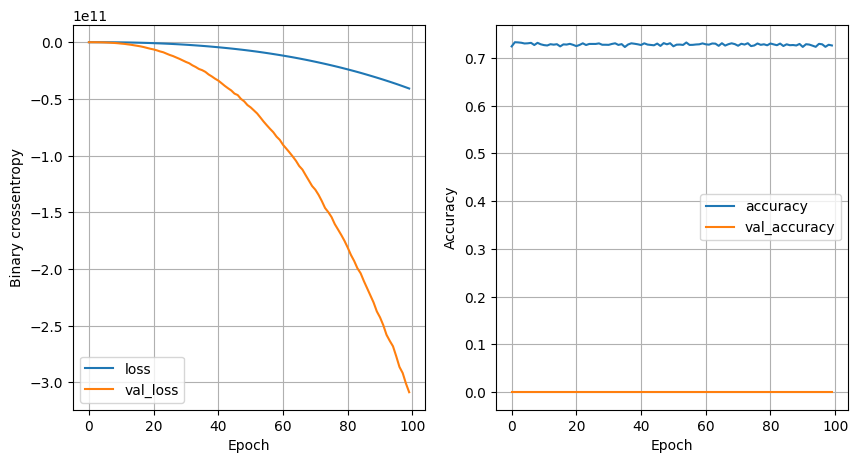

16 nodes , dropout 0 , lr 0.1, batch size 64


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


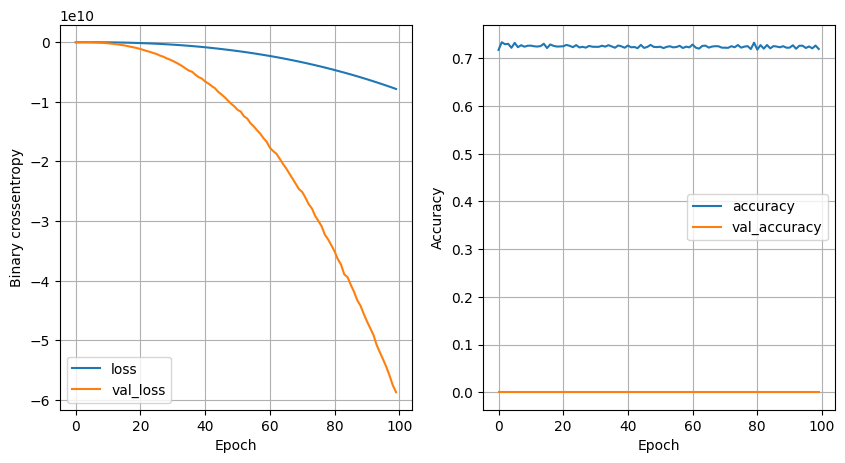

16 nodes , dropout 0 , lr 0.1, batch size 128


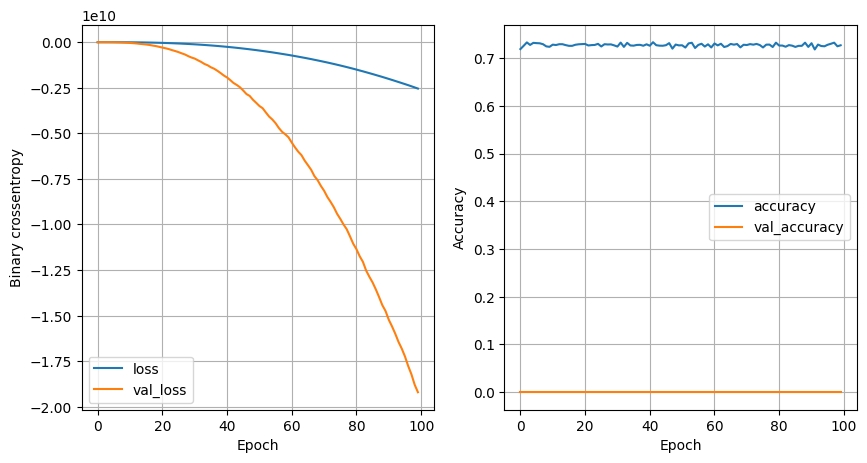

16 nodes , dropout 0 , lr 0.005, batch size 32


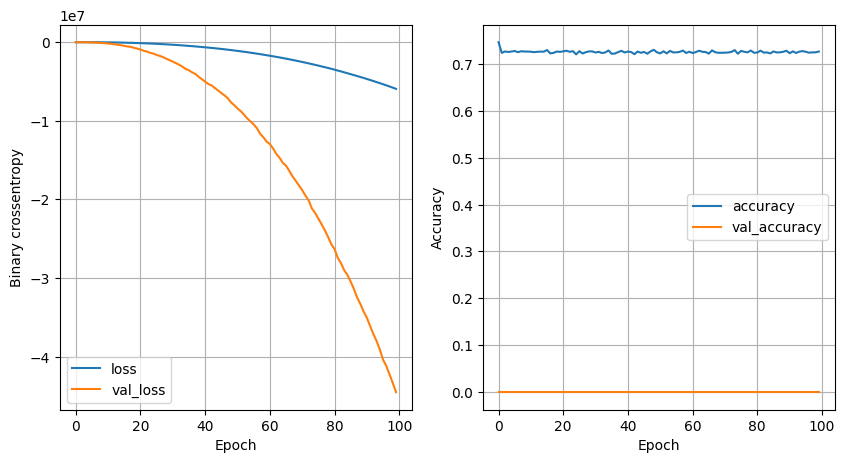

16 nodes , dropout 0 , lr 0.005, batch size 64


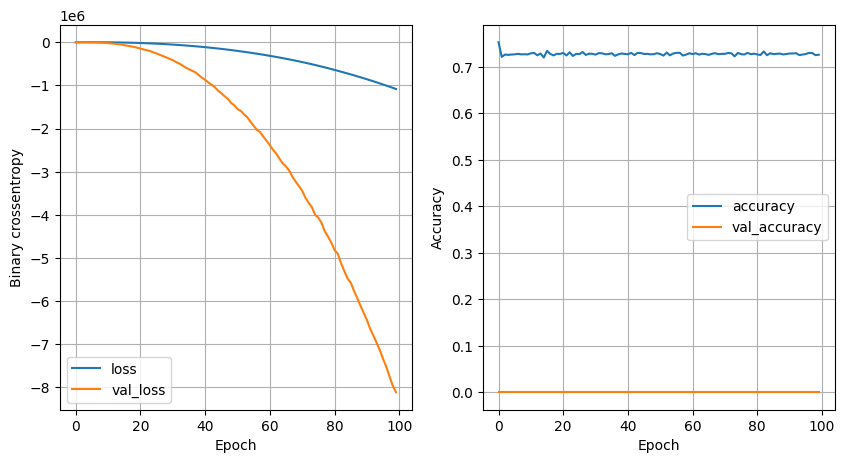

16 nodes , dropout 0 , lr 0.005, batch size 128


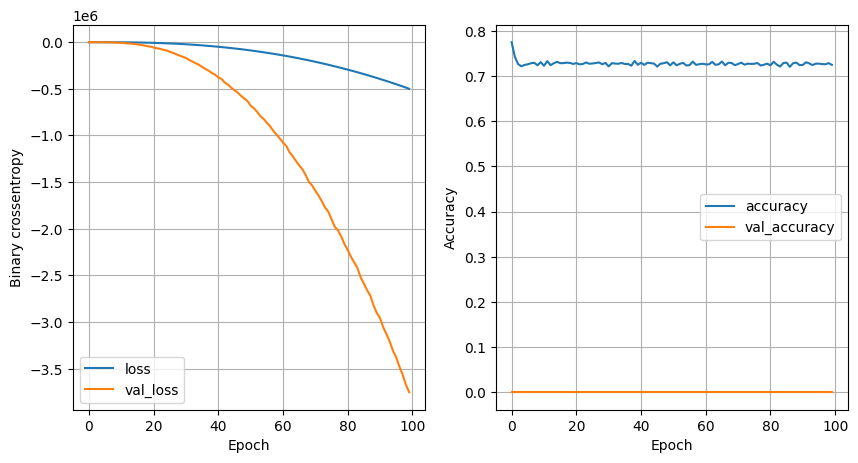

16 nodes , dropout 0 , lr 0.001, batch size 32


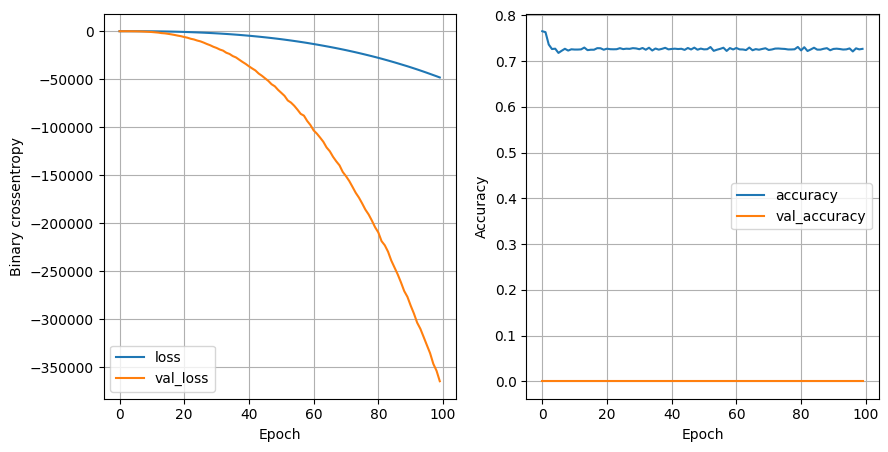

16 nodes , dropout 0 , lr 0.001, batch size 64


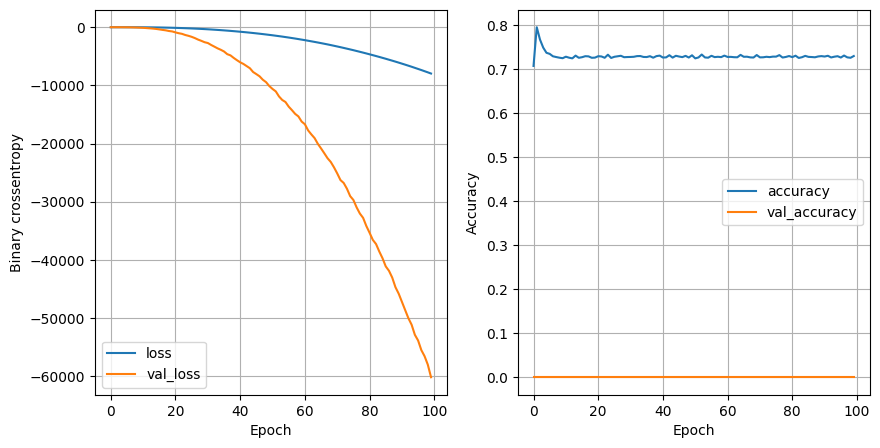

16 nodes , dropout 0 , lr 0.001, batch size 128


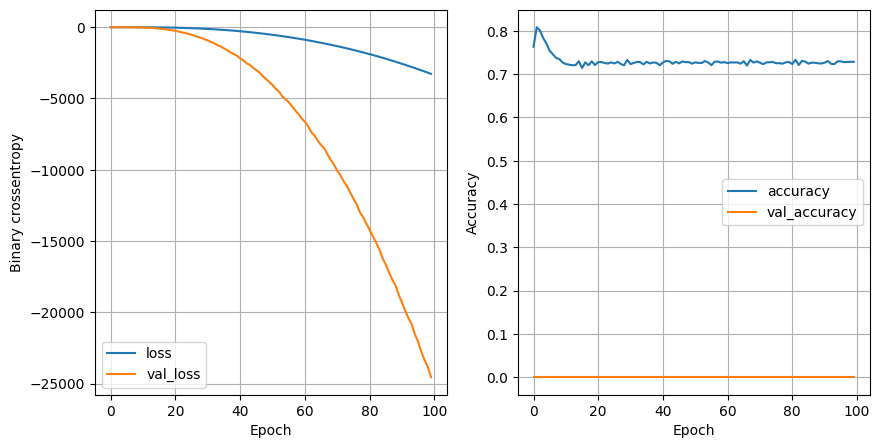

16 nodes , dropout 0.2 , lr 0.1, batch size 32


In [ ]:
least_val_loss = float('inf')
least_val_model = None
epochs = 100

for num_nodes in [16, 32, 64]:
  for dropout_prob in [0, 0.2]:
    for lr in [0.1, 0.005, 0.001]:
      for batch_size in [32, 64, 128]:
        print(f"{num_nodes} nodes , dropout {dropout_prob} , lr {lr}, batch size {batch_size}")
        model, history = train_model(x_train, Y_train, num_nodes, dropout_prob, lr, batch_size, epochs)
        plot_loss(history)

        # Use model.evaluate to get the validation loss
        val_loss, val_acc = model.evaluate(x_valid, Y_valid, verbose=0)
        if val_loss < least_val_loss:
          least_val_loss = val_loss
          least_val_model = model

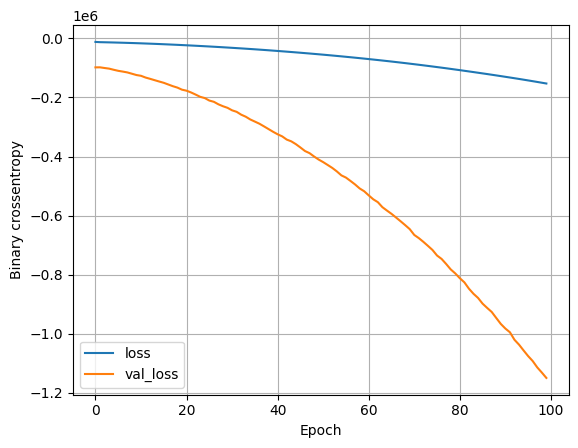

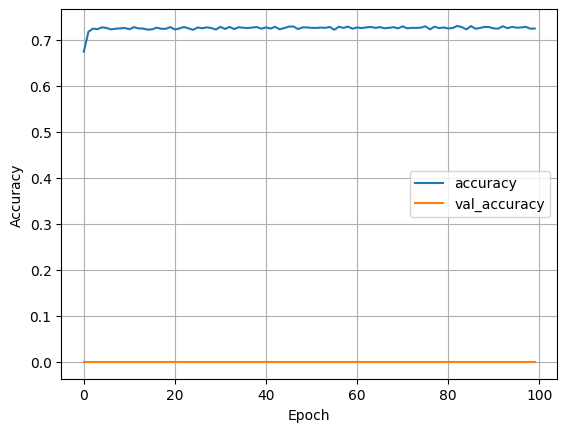

In [ ]:
plot_loss(history)
plot_accuracy(history)

In [ ]:
least_val_model = model.predict(x_test)
y_pred = (least_val_model >= 0.5).astype(int).reshape(-1)
print(classification_report(Y_test, y_pred))